## Load the data and prepare the training window


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cwfc.data import load_cpu, build_targets, split_train_holdout

cpu = load_cpu("../challenge_data/vm_cpu_readings.csv.gz")
meta = pd.read_csv("../challenge_data/vm_metadata.csv.gz")

targets = build_targets(cpu)
train, holdout = split_train_holdout(targets)

# From here on, raw VM readings are also limited to the train window only
train_ts = set(train["timestamp"])
cpu_train = cpu[cpu["timestamp"].isin(train_ts)].copy()
print(cpu_train.shape)   # expect (1_100_000, 5)

(1100000, 5)


**What this shows:** The two targets were built from the full table and then split in time order: the first 110 timestamps are the training window and the last 24 are held out. The raw VM readings were then restricted to the training timestamps (1.1 million rows = 10,000 VMs × 110), so no later analysis uses holdout readings.

## Check VM creation and deletion times


In [18]:
t0, t1 = cpu["timestamp"].min(), cpu["timestamp"].max()
c = meta["timestamp_vm_created"]
d = meta["timestamp_vm_deleted"]

print("trace window:", t0, t1)
print("created/deleted missing:", c.isna().sum(), d.isna().sum())
print("created at or before trace start:", (c <= t0).sum())
print("created inside window:", ((c > t0) & (c <= t1)).sum())
print("created after window end:", (c > t1).sum())
print("deleted inside window:", ((d >= t0) & (d <= t1)).sum())
print("deleted after window end:", (d > t1).sum())

trace window: 0 39900
created/deleted missing: 0 0
created at or before trace start: 10000
created inside window: 0
created after window end: 0
deleted inside window: 0
deleted after window end: 10000


**What this shows:** The trace runs from timestamp 0 to 39,900 s. All 10,000 VMs have a creation time of 0, and none has a deletion time inside the window; the earliest deletion time is 40,500 s, after the last timestamp. The lifecycle fields therefore show no VM arrivals or departures.

This is expected from how the dataset was built: the data card says only VMs with complete traces over the whole window were eligible. So the constant VM count is a property of the selection and says nothing about real churn in Azure. The data card does not define these two fields, so we assume they are in seconds on the same clock as the readings (an assumption, not a documented fact). This check uses only timestamps and metadata, not target values; the earliest deletion being after the last timestamp also suggests the count stays constant over the holdout period.

## Plot active VM count and aggregate CPU over time


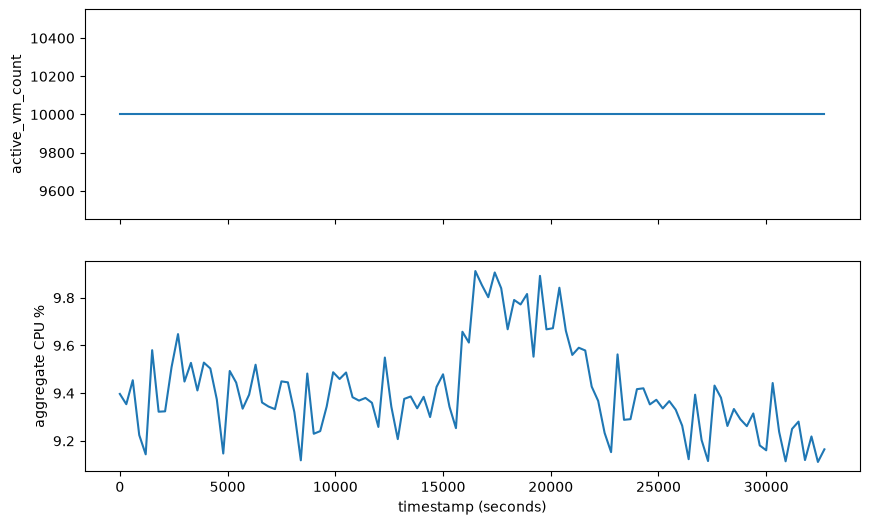

In [19]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(train["timestamp"], train["active_vm_count"])
ax[0].set_ylabel("active_vm_count")
ax[1].plot(train["timestamp"], train["aggregate_cpu_utilization"])
ax[1].set_ylabel("aggregate CPU %")
ax[1].set_xlabel("timestamp (seconds)")
plt.show()

**What this shows:** `active_vm_count` is constant at 10,000 across the training window, so it carries no workload signal and is trivial to forecast. This follows from the dataset design (only VMs with complete traces were selected), not from Azure behavior. Aggregate CPU stays in a narrow band around 9.4% with one broad rise in the middle. Operationally, the forecasting difficulty sits almost entirely in `aggregate_cpu_utilization`.

## Summarize aggregate CPU and define peak periods


In [20]:
col = "aggregate_cpu_utilization"
print(train[[col]].describe())

# Peak definition (decided from train only)
peak_threshold = train[col].quantile(0.90)
train["is_peak"] = train[col] >= peak_threshold
print("peak threshold:", round(peak_threshold, 3))
print(train.loc[train["is_peak"], "timestamp"].tolist())

       aggregate_cpu_utilization
count                 110.000000
mean                    9.414089
std                     0.193568
min                     9.111634
25%                     9.288952
50%                     9.378121
75%                     9.507673
max                     9.912175
peak threshold: 9.668
[16500, 16800, 17100, 17400, 17700, 18300, 18600, 18900, 19500, 20100, 20400]


**What this shows:** Aggregate CPU averages about 9.41% and ranges from 9.11% to 9.91%. The 90th-percentile cutoff is 9.668%; 11 timestamps meet or exceed it, defining the peak periods used in the comparisons below.The aggregate is far calmer (std 0.19 points) than individual VMs (std about 13 points), because averaging 10,000 VMs cancels most individual swings.


## Show where aggregate CPU peaks occur


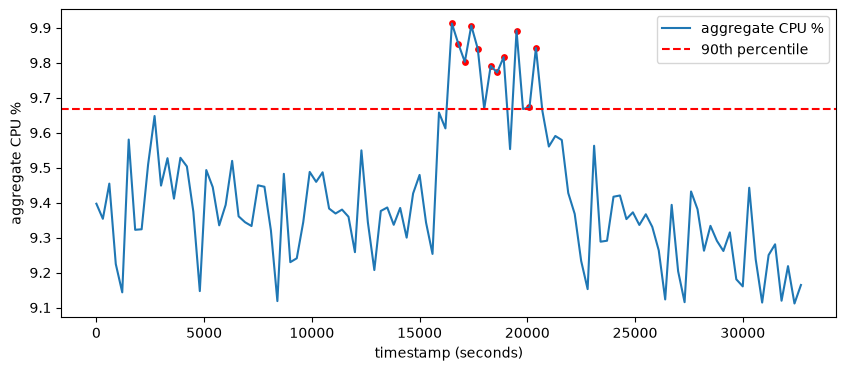

In [21]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(train["timestamp"], train[col], label="aggregate CPU %")
ax.axhline(peak_threshold, color="red", linestyle="--", label="90th percentile")
peaks = train[train["is_peak"]]
ax.scatter(peaks["timestamp"], peaks[col], color="red", s=15)
ax.set_xlabel("timestamp (seconds)")
ax.set_ylabel("aggregate CPU %")
ax.legend()
plt.show()

**What this shows:** The red points mark the peak timestamps and the dashed line is the 90th-percentile cutoff. All peak points fall in one middle stretch of the training window (about 16,500 to 20,400 s). The peak and low flags are descriptive labels for this analysis only and are not used as model features.

## Measure persistence and short-term changes


In [22]:
s = train.set_index("timestamp")[col]

print("autocorrelation lag 1:", round(s.autocorr(1), 3))
print("autocorrelation lag 6 (30 min):", round(s.autocorr(6), 3))
print("autocorrelation lag 12 (1 hour):", round(s.autocorr(12), 3))

step = s.diff().dropna()
print(step.describe())
print("largest one-step jump:", round(step.abs().max(), 3))

autocorrelation lag 1: 0.667
autocorrelation lag 6 (30 min): 0.477
autocorrelation lag 12 (1 hour): 0.367
count    109.000000
mean      -0.002132
std        0.158033
min       -0.274332
25%       -0.109190
50%       -0.020451
75%        0.078342
max        0.436831
Name: aggregate_cpu_utilization, dtype: float64
largest one-step jump: 0.437


**What this shows:** Aggregate CPU is positively correlated across nearby five-minute steps (0.667 at one step), with weaker correlation at 30 minutes (0.477) and one hour (0.367). One-step changes average close to zero, and the largest increase is about 0.437 percentage points.This suggests that recent values help for the next few steps but lose value over a two-hour horizon, so the baselines should include both a last-value and a recent-average version.


## Compare average CPU across VMs


count    10000.000000
mean         9.414089
std         13.051504
min          0.007345
50%          5.501660
75%          9.972827
90%         19.739861
95%         33.625715
99%         79.623001
max         99.272951
Name: avg_cpu, dtype: float64


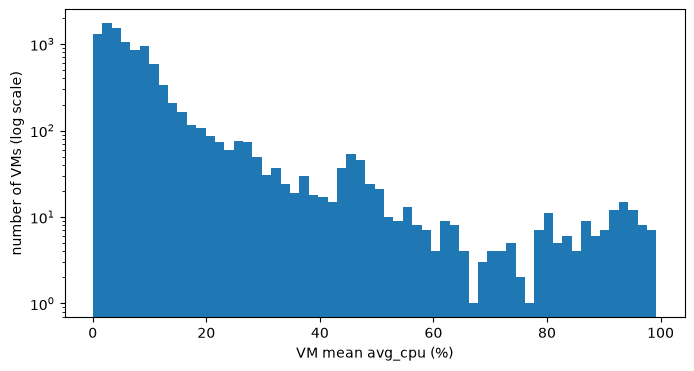

top 1% VMs -> 9.6% of total CPU
top 5% VMs -> 30.0% of total CPU
top 10% VMs -> 43.5% of total CPU


In [23]:
vm_mean = cpu_train.groupby("vm_id")["avg_cpu"].mean()
print(vm_mean.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(vm_mean, bins=60)
ax.set_yscale("log")
ax.set_xlabel("VM mean avg_cpu (%)")
ax.set_ylabel("number of VMs (log scale)")
plt.show()

# How top-heavy is the load?
total = vm_mean.sum()
for q in [0.01, 0.05, 0.10]:
    k = int(len(vm_mean) * q)
    share = vm_mean.sort_values(ascending=False).head(k).sum() / total
    print(f"top {int(q*100)}% VMs -> {share:.1%} of total CPU")

**What this shows:** VM average CPU is strongly uneven: the median is about 5.50%, while the 99th percentile is about 79.62%. The busiest 1%, 5%, and 10% of VMs account for 9.6%, 30.0%, and 43.5% of summed VM averages, respectively, showing that a relatively small group carries a large share of the load.
Operationally, a few busy VMs can move the aggregate, which matters for capacity planning.

## Inspect VM categories and size buckets


In [24]:
print(meta.columns.tolist())
print(meta["vm_category"].value_counts(dropna=False))
print(meta["virtual_core_bucket"].value_counts(dropna=False))
print(meta["memory_gb_bucket"].value_counts(dropna=False))

seg_cols = ["vm_id", "vm_category", "virtual_core_bucket", "memory_gb_bucket"]
cpu_seg = cpu_train.merge(meta[seg_cols], on="vm_id", how="left")
print(cpu_seg[seg_cols[1:]].isna().sum())

['vm_id', 'subscription_id', 'deployment_id', 'timestamp_vm_created', 'timestamp_vm_deleted', 'max_cpu', 'avg_cpu', 'p95_max_cpu', 'vm_category', 'virtual_core_bucket', 'memory_gb_bucket']
vm_category
Delay-insensitive    6180
Interactive          3091
Unknown               729
Name: count, dtype: int64
virtual_core_bucket
2      7534
4      1908
8       486
24       62
>24      10
Name: count, dtype: int64
memory_gb_bucket
2      3904
4      2475
8      2146
32     1383
64       82
>64      10
Name: count, dtype: int64
vm_category            0
virtual_core_bucket    0
memory_gb_bucket       0
dtype: int64


**What this shows:** The metadata includes three VM categories and several core and memory buckets, and the category counts match the data card (6,180 / 3,091 / 729). Delay-insensitive VMs are the largest category, and the two-core bucket is by far the most common. All training readings matched a VM record, so the segment fields have no missing values after the join.

Two cautions. The 10,000 VMs were selected with stratification by category and core bucket, so these shares describe the curated sample, not Azure as a whole. The metadata also holds `avg_cpu`, `max_cpu` and `p95_max_cpu`, which come from the source VM metadata, and the data card does not say which period they cover. They are not used here; every CPU statistic in this notebook is recomputed from the training readings.

## Plot CPU usage by VM category


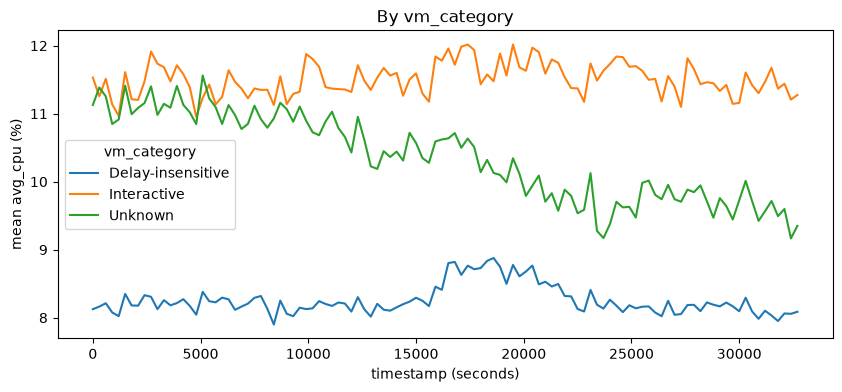

vm_category  Delay-insensitive  Interactive  Unknown
count                   110.00       110.00   110.00
mean                      8.26        11.51    10.35
std                       0.22         0.24     0.63
min                       7.90        10.95     9.17
25%                       8.12        11.35     9.77
50%                       8.19        11.49    10.35
75%                       8.31        11.68    10.91
max                       8.88        12.02    11.56


In [25]:
def segment_series(df, seg):
    return (df.groupby(["timestamp", seg])["avg_cpu"].mean()
              .unstack(seg))

def plot_segment(df, seg):
    wide = segment_series(df, seg)
    fig, ax = plt.subplots(figsize=(10, 4))
    wide.plot(ax=ax)
    ax.set_ylabel("mean avg_cpu (%)")
    ax.set_xlabel("timestamp (seconds)")
    ax.set_title(f"By {seg}")
    plt.show()
    return wide

cat_wide = plot_segment(cpu_seg, "vm_category")
print(cat_wide.describe().round(2))

**What this shows:** The three categories run at different, fairly steady levels. Across the training window, Interactive VMs average about 11.51%, Unknown about 10.35% and Delay-insensitive about 8.26%. The Unknown line varies more (std 0.63 versus about 0.2), most likely because it contains only 729 VMs, so each busy VM moves its average more.

## Plot CPU usage by core and memory size


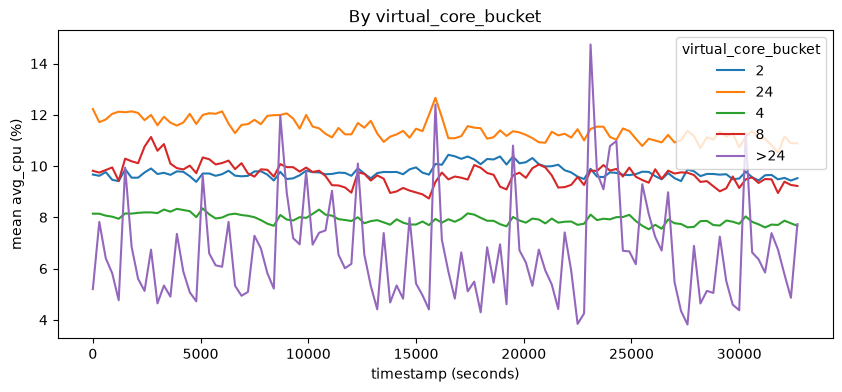

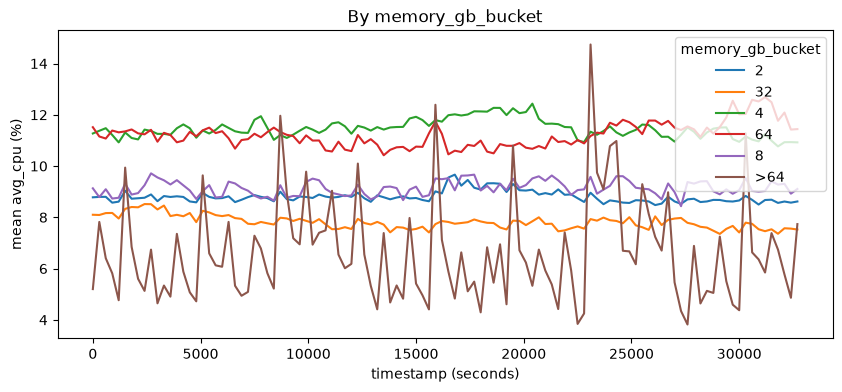

In [26]:
core_wide = plot_segment(cpu_seg, "virtual_core_bucket")
mem_wide = plot_segment(cpu_seg, "memory_gb_bucket")

**What this shows:** The 2-core bucket holds 75% of the VMs (7,534 of 10,000) and sits near the overall average, so it largely sets the aggregate level. The largest buckets are noisy because they hold very few VMs (24-core: 62, >24-core: 10, 64 GB: 82, >64 GB: 10), so conclusions should rely only on the larger groups.

## Compare segment usage during peaks and other periods


In [27]:
peak_ts = set(train.loc[train["is_peak"], "timestamp"])

def peak_lift(wide):
    in_peak = wide.loc[wide.index.isin(peak_ts)].mean()
    off_peak = wide.loc[~wide.index.isin(peak_ts)].mean()
    return pd.DataFrame({"off_peak": off_peak, "peak": in_peak,
                         "lift": in_peak - off_peak}).round(3)

print(peak_lift(cat_wide))
print(peak_lift(core_wide))
print(peak_lift(mem_wide))

                   off_peak    peak   lift
vm_category                               
Delay-insensitive     8.201   8.765  0.564
Interactive          11.469  11.833  0.365
Unknown              10.358  10.329 -0.029
                     off_peak    peak   lift
virtual_core_bucket                         
2                       9.703  10.316  0.613
24                     11.450  11.241 -0.209
4                       7.918   7.925  0.007
8                       9.663   9.618 -0.044
>24                     6.652   6.322 -0.330
                  off_peak    peak   lift
memory_gb_bucket                         
2                    8.745   9.314  0.568
32                   7.817   7.786 -0.031
4                   11.384  12.143  0.760
64                  11.279  10.664 -0.614
8                    9.116   9.390  0.274
>64                  6.652   6.322 -0.330


**What this shows:** During peaks, Delay-insensitive (+0.56) and Interactive (+0.37) categories rise while Unknown is unchanged. By size, 2-core VMs (+0.61) and 4 GB VMs (+0.76) rise most. The apparent drops in 64 GB (−0.61) and >24-core (−0.33) buckets come from very small groups (82 and 10 VMs) and are probably noise. These are descriptive differences, not proof that any segment caused the peak.


## Review CPU levels and burst gaps


In [28]:
print(cpu_train[["min_cpu", "avg_cpu", "max_cpu"]].describe(
    percentiles=[0.5, 0.9, 0.99]).round(2))

# Gap between max and avg shows how bursty readings are
cpu_train["burst_gap"] = cpu_train["max_cpu"] - cpu_train["avg_cpu"]
print(cpu_train["burst_gap"].describe().round(2))

          min_cpu     avg_cpu     max_cpu
count  1100000.00  1100000.00  1100000.00
mean         6.15        9.41       18.44
std         11.75       14.28       21.69
min          0.00        0.01        0.02
50%          3.23        5.12        9.18
90%         11.22       19.69       52.22
99%         78.26       87.41       97.58
max         99.28       99.49       99.70
count    1100000.00
mean           9.03
std           12.88
min            0.00
25%            1.24
50%            3.31
75%           10.78
max           95.52
Name: burst_gap, dtype: float64


**What this shows:** Across training readings, average CPU is 9.41% while maximum CPU averages 18.44%, and the typical gap between maximum and average is 3.31 points. The gap can be as large as 95.52 points, which shows that individual readings can include sharp bursts even when their average is modest.


## Summarize VM lifetime metadata


In [29]:
life = meta[["vm_id", "timestamp_vm_created", "timestamp_vm_deleted"]]
print(life.describe())
print(life["timestamp_vm_created"].value_counts().head())
print(life["timestamp_vm_deleted"].value_counts().head())

       timestamp_vm_created  timestamp_vm_deleted
count               10000.0          1.000000e+04
mean                    0.0          2.289626e+06
std                     0.0          7.081008e+05
min                     0.0          4.050000e+04
25%                     0.0          2.591400e+06
50%                     0.0          2.591400e+06
75%                     0.0          2.591400e+06
max                     0.0          2.591400e+06
timestamp_vm_created
0    10000
Name: count, dtype: int64
timestamp_vm_deleted
2591400    8213
736500       50
1537200      42
743100       37
352200       20
Name: count, dtype: int64


**What this shows:** All VMs have a creation timestamp of 0. Most deletion timestamps (8,213 VMs) are 2,591,400 s, far beyond the observed trace, and some VMs have earlier deletion times (for example 736,500 s for 50 VMs); the earliest is 40,500 s. This agrees with the window check above: no recorded deletion falls inside the observed period.

The value 2,591,400 s is just under 30 days (30 days minus 10 minutes). The data card does not explain it, so our reading that it marks the end of the source trace is an assumption.

## Find continuous peak and low periods


PEAK runs
     start    end  n  minutes
run                          
2    16500  17700  5       25
4    18300  18900  3       15
6    19500  19500  1        5
8    20100  20400  2       10
LOW runs
     start    end  n  minutes
run                          
2     1200   1200  1        5
4     4800   4800  1        5
6     8400   8400  1        5
8    22800  22800  1        5
10   26400  26400  1        5
12   27300  27300  1        5
14   30000  30000  1        5
16   30900  30900  1        5
18   31800  31800  1        5
20   32400  32700  2       10
timestamp
1500     0.437
23100    0.410
15900    0.404
8700     0.364
5100     0.346
Name: aggregate_cpu_utilization, dtype: float64


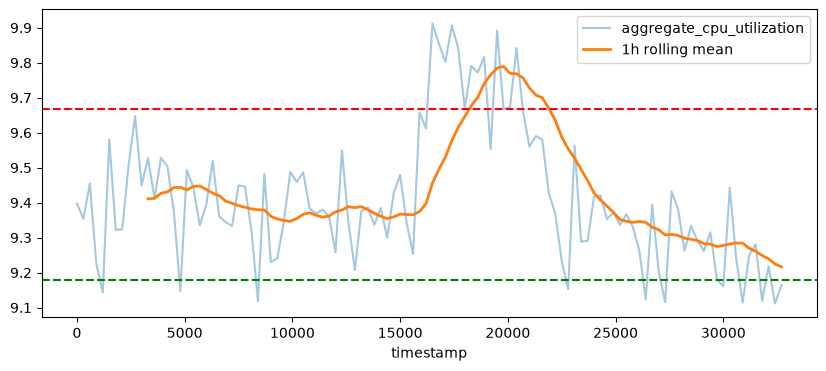

In [30]:
col = "aggregate_cpu_utilization"
low_threshold = train[col].quantile(0.10)
train["is_low"] = train[col] <= low_threshold

def runs_of(flag):
    run_id = (flag != flag.shift()).cumsum()
    r = (train.assign(run=run_id)[flag]
              .groupby("run")["timestamp"].agg(start="min", end="max", n="count"))
    r["minutes"] = r["n"] * 5
    return r

print("PEAK runs"); print(runs_of(train["is_peak"]))
print("LOW runs");  print(runs_of(train["is_low"]))

# How abrupt is the climb into the main peak?
s = train.set_index("timestamp")[col]
print(s.diff().nlargest(5).round(3))

# Trend: 1-hour rolling mean
ax = s.plot(alpha=0.4, figsize=(10, 4))
s.rolling(12).mean().plot(ax=ax, linewidth=2, label="1h rolling mean")
ax.axhline(peak_threshold, color="red", linestyle="--")
ax.axhline(low_threshold, color="green", linestyle="--")
ax.legend(); plt.show()

**What this shows:** The above-threshold timestamps form four runs of 25, 15, 5 and 10 minutes, all inside one broad hump (about 16,500 to 20,400 s). Low points are mostly isolated single readings, so there is no sustained low-demand period. The largest one-step increases (0.35 to 0.44 points) occur at scattered times, one of them right before the hump (15,900 s), so ordinary noise looks similar to the start of a peak. Operationally, peaks last tens of minutes, not hours, and their start cannot be told apart from noise ahead of time, so peak errors should be reported separately.

**Key takeaways for modeling**

1. `active_vm_count` is constant at 10,000, so a last-value forecast is expected to be exact. This is a result of the dataset design (only VMs with complete traces were selected), not evidence about real Azure churn. The metadata shows no deletions before 40,500 s, which also supports a constant count over the holdout. Percentage-based errors are meaningless for this target because the error and the baseline error are zero.

2. `aggregate_cpu_utilization` is stable (9.41% mean, std 0.19) with one broad hump; lag-1 autocorrelation is 0.67 and falls to 0.37 at one hour.

3. Load is concentrated in a few busy VMs. During the hump, 2-core and small-memory VMs show the largest rise, though this is descriptive and not proof of cause.

4. With only about 11 hours of data, daily or weekly seasonality cannot be tested, so no seasonal baseline is justified.

5. The high-load threshold (90th percentile of the training window, 9.668%) will be used to report peak-period errors separately. It will be recomputed from the training data in code, not typed in by hand.

6. The peak and low flags in this notebook are for description only and will not be used as model features.

7. The sample is stratified by category and core bucket and contains only complete-trace VMs, so results describe this curated sample and should not be generalized to all of Azure.